# 04 — Multimodal fusion, final comparison, error analysis

Inputs: `alprotein_outputs/` from notebooks 01–03. CPU runtime is enough (image features are already cached).

Plan:
1. Put numerical and image features in one table (aligned by **plant** and **time**).
2. Re-run the best numerical and image models and three **fusion** strategies with the *same* folds.
3. Final comparison table + a paired bootstrap test: does fusion really beat numerical-only?
4. Error analysis: where and why the models fail, with image + environmental history for specific plants.

In [1]:
# --- Setup -------------------------------------------------------------------
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_DIR = Path('/content/drive/MyDrive/25 tomato dataset') if IN_COLAB else Path(os.environ.get('DATA_DIR', 'data'))
MONTH_DIR = DATA_DIR / '2025' / '202506'
OUT_DIR = DATA_DIR.parent / 'alprotein_outputs'
FIG_DIR = OUT_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
assert (OUT_DIR / 'image_features_plant.parquet').exists(), 'Run notebooks 01–03 first'

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

num = pd.read_parquet(OUT_DIR / 'model_table_numerical.parquet')
img = pd.read_parquet(OUT_DIR / 'image_features_plant.parquet')
zone_ts = pd.read_parquet(OUT_DIR / 'sensors_zone_30min.parquet')
images = pd.read_parquet(OUT_DIR / 'image_index.parquet')
win = json.loads((OUT_DIR / 'target_window.json').read_text())
T0, T1 = pd.Timestamp(win['T0']), pd.Timestamp(win['T1'])

df = num.merge(img, on='plant', how='inner', validate='one_to_one')
print('plants after alignment:', len(df), '(numerical:', len(num), ', image:', len(img), ')')

Mounted at /content/drive
plants after alignment: 60 (numerical: 60 , image: 60 )


## 1. How the two modalities are aligned

| | numerical | image |
|---|---|---|
| **plant** | plant ID → its sensor zone (`plant_map.csv`), its own measurements on t0 | plant ID → camera folder → bed (left/right) → cell (variety column, replicate row) |
| **time** | phenotype on t0 (7 June); sensors aggregated over [t0, t1) | images on t0 and t1 at ~10:00 and ~14:00, averaged per day |
| **target** | height(t1) − height(t0), measured by hand | same |

Nothing measured on t1 by hand is used as an input. Two settings are compared:
- **forecast** — only information available on t0 (phenotype, t0 images) + the sensor history of the interval;
- **estimation** — t1 images are also used: the camera *sees* the growth that already happened, replacing a manual measurement.

In [2]:
PHENO_FEATS = [c for c in num.columns if c.endswith('_t0') and not c.startswith(('cell_', 'bed_'))] + ['variety_cherry']
SENSOR_CANDIDATES = ['temp_mean', 'temp_max_daily', 'temp_min_daily', 'gdd_base10', 'light_sum', 'light_day_mean',
                     'rh_mean', 'vpd_mean', 'vpd_day_mean', 'co2_day_mean', 'soil_moisture_change', 'soil_temp_rel_mean']
SENSOR_FEATS = [c for c in SENSOR_CANDIDATES if c in num.columns]
HC_FEATS = [c for c in img.columns if c.startswith(('cell_', 'bed_'))]
EMB_FEATS = [c for c in img.columns if c.startswith(('emb_cell_t1', 'emb_cell_delta', 'emb_bed_delta'))]
HC_T0 = [c for c in HC_FEATS if c.endswith('_t0')]                       # what the camera shows on 7 June
EMB_T0 = [c for c in img.columns if c.startswith(('emb_cell_t0', 'emb_bed_t0'))]
NUM_FEATS = PHENO_FEATS + SENSOR_FEATS
print(len(PHENO_FEATS), 'phenotype |', len(SENSOR_FEATS), 'sensor |', len(HC_FEATS), 'image hand-crafted (', len(HC_T0), 't0 only) |',
      len(EMB_FEATS), 'embedding (', len(EMB_T0), 't0 only)')

11 phenotype | 12 sensor | 42 image hand-crafted ( 14 t0 only) | 6144 embedding ( 4096 t0 only)


## 2. Models and fusion strategies

All models share the same folds and the same safety rule: **predictions are clipped to the range of the training targets**.
(In notebook 03, one Ridge model predicted absurd values for an unseen camera because image features of that camera were
outside the training range — clipping prevents a single extrapolation from dominating RMSE.)

Fusion strategies:
1. **Early fusion (compact):** numerical + hand-crafted image features in one Ridge / Random Forest.
2. **Early fusion (full):** numerical + hand-crafted + CNN embeddings (PCA 10 inside the fold).
3. **Late fusion:** train the best numerical model and the best image model separately, average their predictions.

Each strategy is run in the **estimation** setting (t0 + t1 images) and the **forecast** setting (t0 images only).

In [3]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RepeatedKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

N_PCA = 10

class Clipped(BaseEstimator, RegressorMixin):
    """Wrap a regressor and clip predictions to the training-target range."""
    def __init__(self, est):
        self.est = est
    def fit(self, X, y):
        self.est_ = clone(self.est).fit(X, y); self.lo_, self.hi_ = np.min(y), np.max(y); return self
    def predict(self, X):
        return np.clip(self.est_.predict(X), self.lo_, self.hi_)

class Average(BaseEstimator, RegressorMixin):
    """Late fusion: fit each model on its own columns, average the predictions."""
    def __init__(self, models):
        self.models = models          # list of (estimator, columns)
    def fit(self, X, y):
        self.fitted_ = [(clone(m).fit(X[cols], y), cols) for m, cols in self.models]; return self
    def predict(self, X):
        return np.mean([m.predict(X[cols]) for m, cols in self.fitted_], axis=0)

def prep(plain_cols, emb_cols=()):
    parts = [('plain', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), list(plain_cols))]
    if emb_cols:
        parts.append(('emb', make_pipeline(StandardScaler(), PCA(n_components=N_PCA, random_state=SEED)), list(emb_cols)))
    return ColumnTransformer(parts)

def ridge(plain, emb=()):
    return Clipped(make_pipeline(prep(plain, emb), RidgeCV(alphas=np.logspace(-2, 3, 30))))
def forest(plain, emb=()):
    return Clipped(make_pipeline(prep(plain, emb),
                                 RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED)))

MODELS = {
    'baseline (mean)':               (lambda: DummyRegressor(), NUM_FEATS),
    'numerical | RF':                (lambda: forest(NUM_FEATS), NUM_FEATS),
    'numerical | ridge':             (lambda: ridge(NUM_FEATS), NUM_FEATS),
    'image (hand-crafted) | RF':     (lambda: forest(HC_FEATS), HC_FEATS),
    'image (all) | RF':              (lambda: forest(HC_FEATS, EMB_FEATS), HC_FEATS + EMB_FEATS),
    'fusion early compact | RF':     (lambda: forest(NUM_FEATS + HC_FEATS), NUM_FEATS + HC_FEATS),
    'fusion early compact | ridge':  (lambda: ridge(NUM_FEATS + HC_FEATS), NUM_FEATS + HC_FEATS),
    'fusion early full | RF':        (lambda: forest(NUM_FEATS + HC_FEATS, EMB_FEATS), NUM_FEATS + HC_FEATS + EMB_FEATS),
    'fusion late (num RF + img RF)': (lambda: Average([(forest(NUM_FEATS), NUM_FEATS),
                                                       (forest(HC_FEATS, EMB_FEATS), HC_FEATS + EMB_FEATS)]),
                                      NUM_FEATS + HC_FEATS + EMB_FEATS),
    # forecast setting: images of 7 June only
    'image t0-only (all) | RF':      (lambda: forest(HC_T0, EMB_T0), HC_T0 + EMB_T0),
    'fusion forecast early | RF':    (lambda: forest(NUM_FEATS + HC_T0), NUM_FEATS + HC_T0),
    'fusion forecast late | RF':     (lambda: Average([(forest(NUM_FEATS), NUM_FEATS),
                                                       (forest(HC_T0, EMB_T0), HC_T0 + EMB_T0)]),
                                      NUM_FEATS + HC_T0 + EMB_T0),
}

In [4]:
y = df['y'].values
groups = df['camera'].astype(str).values

def oof_predict(make_model, X, scheme):
    pred_sum, pred_n = np.zeros(len(y)), np.zeros(len(y))
    splits = (RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(X) if scheme == 'kfold'
              else LeaveOneGroupOut().split(X, y, groups))
    for tr, te in splits:
        m = make_model().fit(X.iloc[tr], y[tr])
        pred_sum[te] += m.predict(X.iloc[te]); pred_n[te] += 1
    return pred_sum / pred_n

def scores(pred):
    return {'MAE': mean_absolute_error(y, pred), 'RMSE': mean_squared_error(y, pred) ** 0.5, 'R2': r2_score(y, pred)}

results, oof = [], {}
for scheme in ['leave_camera_out', 'kfold']:
    for name, (mk, cols) in MODELS.items():
        p = oof_predict(mk, df[cols], scheme)
        oof[(scheme, name)] = p
        results.append({'scheme': scheme, 'model': name, **scores(p)})
        print(f'{scheme:17s} {name:32s} R2={results[-1]["R2"]:.3f}')

final = pd.DataFrame(results)
final.to_csv(OUT_DIR / 'results_final.csv', index=False)
display(final.pivot_table(index='model', columns='scheme', values=['MAE', 'RMSE', 'R2']).round(3)
        .sort_values(('R2', 'leave_camera_out'), ascending=False))

leave_camera_out  baseline (mean)                  R2=-0.053
leave_camera_out  numerical | RF                   R2=0.201
leave_camera_out  numerical | ridge                R2=0.153
leave_camera_out  image (hand-crafted) | RF        R2=0.004
leave_camera_out  image (all) | RF                 R2=0.000
leave_camera_out  fusion early compact | RF        R2=0.090
leave_camera_out  fusion early compact | ridge     R2=-0.066
leave_camera_out  fusion early full | RF           R2=0.092
leave_camera_out  fusion late (num RF + img RF)    R2=0.178
leave_camera_out  image t0-only (all) | RF         R2=0.014
leave_camera_out  fusion forecast early | RF       R2=0.123
leave_camera_out  fusion forecast late | RF        R2=0.165
kfold             baseline (mean)                  R2=-0.026
kfold             numerical | RF                   R2=0.248
kfold             numerical | ridge                R2=0.208
kfold             image (hand-crafted) | RF        R2=0.163
kfold             image (all) | RF   

MAE                      R2                     RMSE                 
scheme                         kfold leave_camera_out  kfold leave_camera_out   kfold leave_camera_out
model                                                                                                 
numerical | RF                 6.632            6.805  0.248            0.201   9.268            9.556
fusion late (num RF + img RF)  6.644            7.339  0.258            0.178   9.205            9.691
fusion forecast late | RF      6.586            7.062  0.249            0.165   9.264            9.768
numerical | ridge              6.950            6.978  0.208            0.153   9.513            9.835
fusion forecast early | RF     6.877            7.242  0.212            0.123   9.488           10.008
fusion early full | RF         6.848            7.781  0.235            0.092   9.347           10.184
fusion early compact | RF      6.748            7.421  0.221            0.090   9.434           10.197
image t0-only (all) | RF       7.171            7.663  0.171            0.014   9.732           10.613
image (hand-crafted) | RF      7.188            7.971  0.163            0.004   9.780           10.668
image (all) | RF               7.195            8.380  0.199            0.000   9.567           10.685
baseline (mean)                8.323            8.366 -0.026           -0.053  10.828           10.968
fusion early compact | ridge   6.964            8.396  0.186           -0.066   9.644           11.035

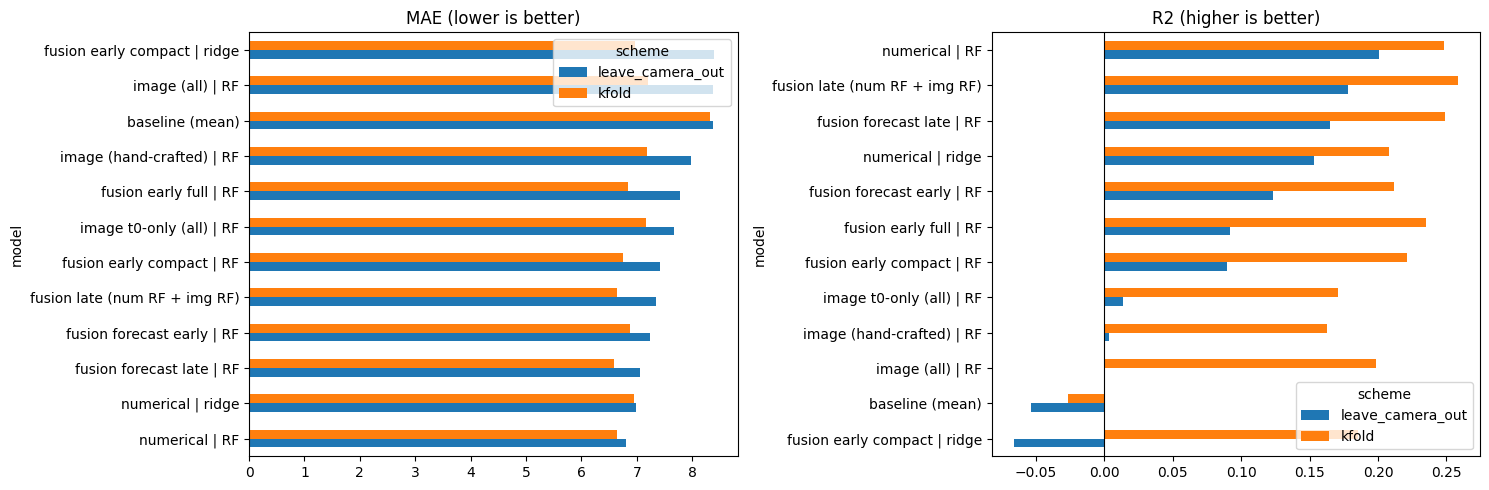

In [5]:
# Visual comparison (leave-camera-out = the stricter, headline scheme)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['MAE', 'R2']):
    t = final.pivot_table(index='model', columns='scheme', values=metric).sort_values('leave_camera_out')
    t[['leave_camera_out', 'kfold']].plot.barh(ax=ax)
    ax.set_title(metric + (' (lower is better)' if metric == 'MAE' else ' (higher is better)'))
    if metric == 'R2':
        ax.axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'model_comparison.png', dpi=150); plt.show()

## 3. Is the fusion gain real? Paired bootstrap

With 60 plants a small difference in MAE can be noise. For each plant we compare the absolute error of
model A and model B, resample plants 5000 times, and look at the 95 % interval of the MAE difference.
If the interval contains 0, we **cannot claim** that one model is better.

In [6]:
rng = np.random.default_rng(SEED)
def paired_bootstrap(a, b, scheme='leave_camera_out', n=5000):
    ea, eb = np.abs(y - oof[(scheme, a)]), np.abs(y - oof[(scheme, b)])
    d = ea - eb                                    # > 0 means B has the smaller error
    boots = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {'A': a, 'B': b, 'MAE_A - MAE_B': d.mean(), 'CI95_low': lo, 'CI95_high': hi,
            'B better in % of plants': (d > 0).mean() * 100}

pairs = [('numerical | RF', 'fusion forecast early | RF'),
         ('numerical | RF', 'fusion forecast late | RF'),
         ('numerical | RF', 'fusion early compact | RF'),
         ('numerical | RF', 'fusion early full | RF'),
         ('numerical | RF', 'fusion late (num RF + img RF)'),
         ('image (all) | RF', 'fusion late (num RF + img RF)'),
         ('baseline (mean)', 'numerical | RF'),
         ('baseline (mean)', 'image (all) | RF'),
         ('baseline (mean)', 'image t0-only (all) | RF')]
boot = pd.DataFrame([paired_bootstrap(a, b) for a, b in pairs])
display(boot.round(2))

,A,B,MAE_A - MAE_B,CI95_low,CI95_high,B better in % of plants
0,numerical | RF,fusion forecast early | RF,-0.44,-1.51,0.62,45.00
1,numerical | RF,fusion forecast late | RF,-0.26,-0.84,0.35,41.67
2,numerical | RF,fusion early compact | RF,-0.62,-1.70,0.50,40.00
3,numerical | RF,fusion early full | RF,-0.98,-2.06,0.12,40.00
4,numerical | RF,fusion late (num RF + img RF),-0.53,-1.20,0.16,40.00
5,image (all) | RF,fusion late (num RF + img RF),1.04,0.37,1.72,65.00
6,baseline (mean),numerical | RF,1.56,0.58,2.45,68.33
7,baseline (mean),image (all) | RF,-0.01,-0.89,0.86,53.33
8,baseline (mean),image t0-only (all) | RF,0.70,0.07,1.36,63.33


## 4. Error analysis

Positive residual = the model **under-estimated** growth (plant grew more than predicted).

In [7]:
BEST_FUSION = final[(final.scheme == 'leave_camera_out') & final.model.str.startswith('fusion')] \
                .sort_values('MAE').iloc[0]['model']
print('fusion model used for error analysis:', BEST_FUSION)

df['pred_num'] = oof[('leave_camera_out', 'numerical | RF')]
df['pred_img'] = oof[('leave_camera_out', 'image (all) | RF')]
df['pred_fus'] = oof[('leave_camera_out', BEST_FUSION)]
for k in ['num', 'img', 'fus']:
    df[f'res_{k}'] = df['y'] - df[f'pred_{k}']

cols = ['plant', 'camera', 'sensor_zone', 'zone_is_proxy', 'treatment', 'variety_name', 'Plant Height_t0', 'y',
        'pred_num', 'pred_img', 'pred_fus', 'res_fus']
print('Largest UNDER-estimations (fusion):')
display(df.sort_values('res_fus', ascending=False)[cols].head(6).round(1))
print('Largest OVER-estimations (fusion):')
display(df.sort_values('res_fus')[cols].head(6).round(1))

fusion model used for error analysis: fusion forecast late | RF
Largest UNDER-estimations (fusion):


,plant,camera,sensor_zone,zone_is_proxy,treatment,variety_name,Plant Height_t0,y,pred_num,pred_img,pred_fus,res_fus
35,L423,11411,GH_MEAN,True,T4,Jinzhu (cherry),192.0,57.0,23.4,24.8,20.8,36.2
34,L422,11411,GH_MEAN,True,T4,Jinzhu (cherry),189.0,36.0,22.5,23.8,19.6,16.4
25,CK12,11411,CK2,False,CK,Guanghui 201,242.0,31.0,14.0,17.3,17.4,13.6
39,L521,511611,T5,False,T5,Jinzhu (cherry),208.0,30.0,19.9,16.7,18.4,11.6
33,L421,11411,GH_MEAN,True,T4,Jinzhu (cherry),194.0,31.0,20.4,23.7,19.5,11.5
38,L513,511611,T5,False,T5,Guanghui 201,181.0,32.0,23.6,15.1,20.9,11.1


Largest OVER-estimations (fusion):


,plant,camera,sensor_zone,zone_is_proxy,treatment,variety_name,Plant Height_t0,y,pred_num,pred_img,pred_fus,res_fus
2,L113,111211,T1,False,T1,Guanghui 201,218.0,-13.0,19.4,16.8,18.4,-31.4
50,L516,514614,T5,False,T5,Guanghui 201,149.0,2.0,19.0,20.3,20.5,-18.5
44,L613,511611,T6,False,T6,Guanghui 201,216.0,1.0,15.7,15.9,16.8,-15.8
54,L614,514614,T6,False,T6,Guanghui 201,144.0,2.0,10.8,20.5,16.7,-14.7
49,L515,514614,T5,False,T5,Guanghui 201,166.0,6.0,19.0,19.5,20.4,-14.4
46,L622,511611,T6,False,T6,Jinzhu (cherry),173.0,2.0,15.1,19.4,16.2,-14.2


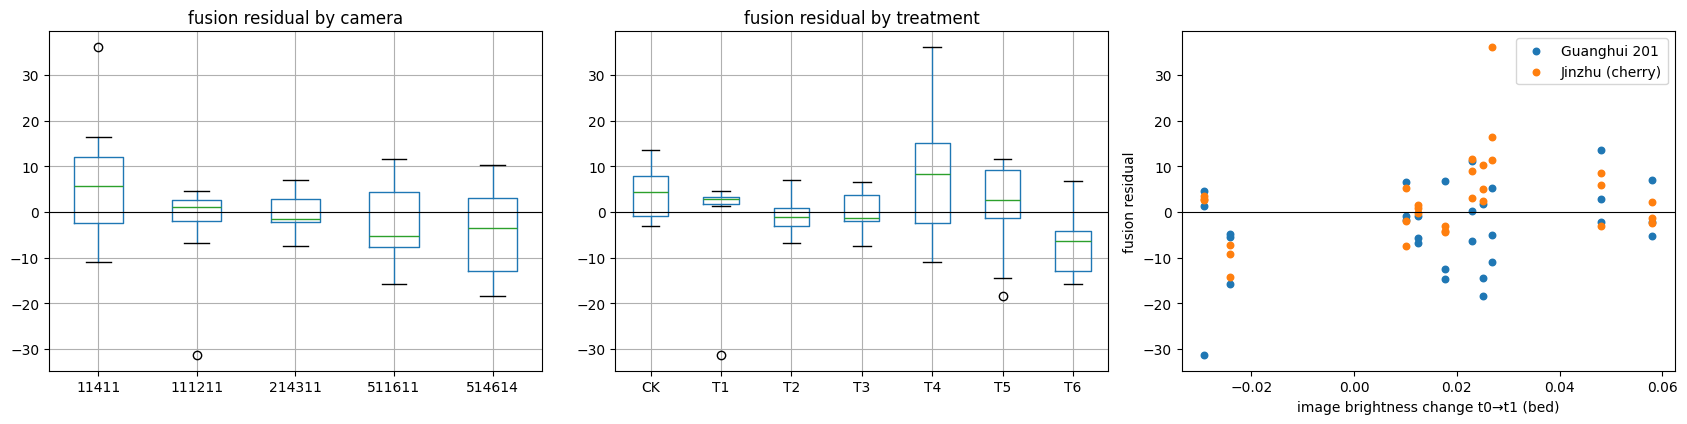

Mean absolute residual by variety:


,res_num,res_img,res_fus
variety_name,,,
Guanghui 201,7.22,9.01,7.56
Jinzhu (cherry),6.39,7.75,6.56


Mean residual for plants with / without their own sensor:


,res_num,res_fus
zone_is_proxy,,
False,-1.32,-1.63
True,3.37,4.41


In [8]:
# Are errors structured? (by group, and against image brightness change = lighting artefact check)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, g in zip(axes[:2], ['camera', 'treatment']):
    df.boxplot(column='res_fus', by=g, ax=ax); ax.axhline(0, color='k', lw=.8)
    ax.set_title(f'fusion residual by {g}'); ax.set_xlabel('')
bcol = 'bed_brightness_delta' if 'bed_brightness_delta' in df else None
if bcol:
    for v, g in df.groupby('variety_name'):
        axes[2].scatter(g[bcol], g['res_fus'], label=v, s=22)
    axes[2].axhline(0, color='k', lw=.8); axes[2].legend()
    axes[2].set_xlabel('image brightness change t0→t1 (bed)'); axes[2].set_ylabel('fusion residual')
plt.suptitle(''); plt.tight_layout(); plt.savefig(FIG_DIR / 'residuals.png', dpi=150); plt.show()

print('Mean absolute residual by variety:'); display(df.groupby('variety_name')[['res_num', 'res_img', 'res_fus']].apply(lambda r: r.abs().mean()).round(2))
print('Mean residual for plants with / without their own sensor:'); display(df.groupby('zone_is_proxy')[['res_num', 'res_fus']].mean().round(2))

### 4.1 Detailed case: under-estimated growth

*"The model underestimated plant growth even though temperature and light conditions appeared favorable.
Inspect the image and recent environmental history and explain what information may be missing or misleading."*

We take the most under-estimated plant and put side by side: its image region on t0 and t1,
the environmental history the model saw, and how it compares with the other plants.

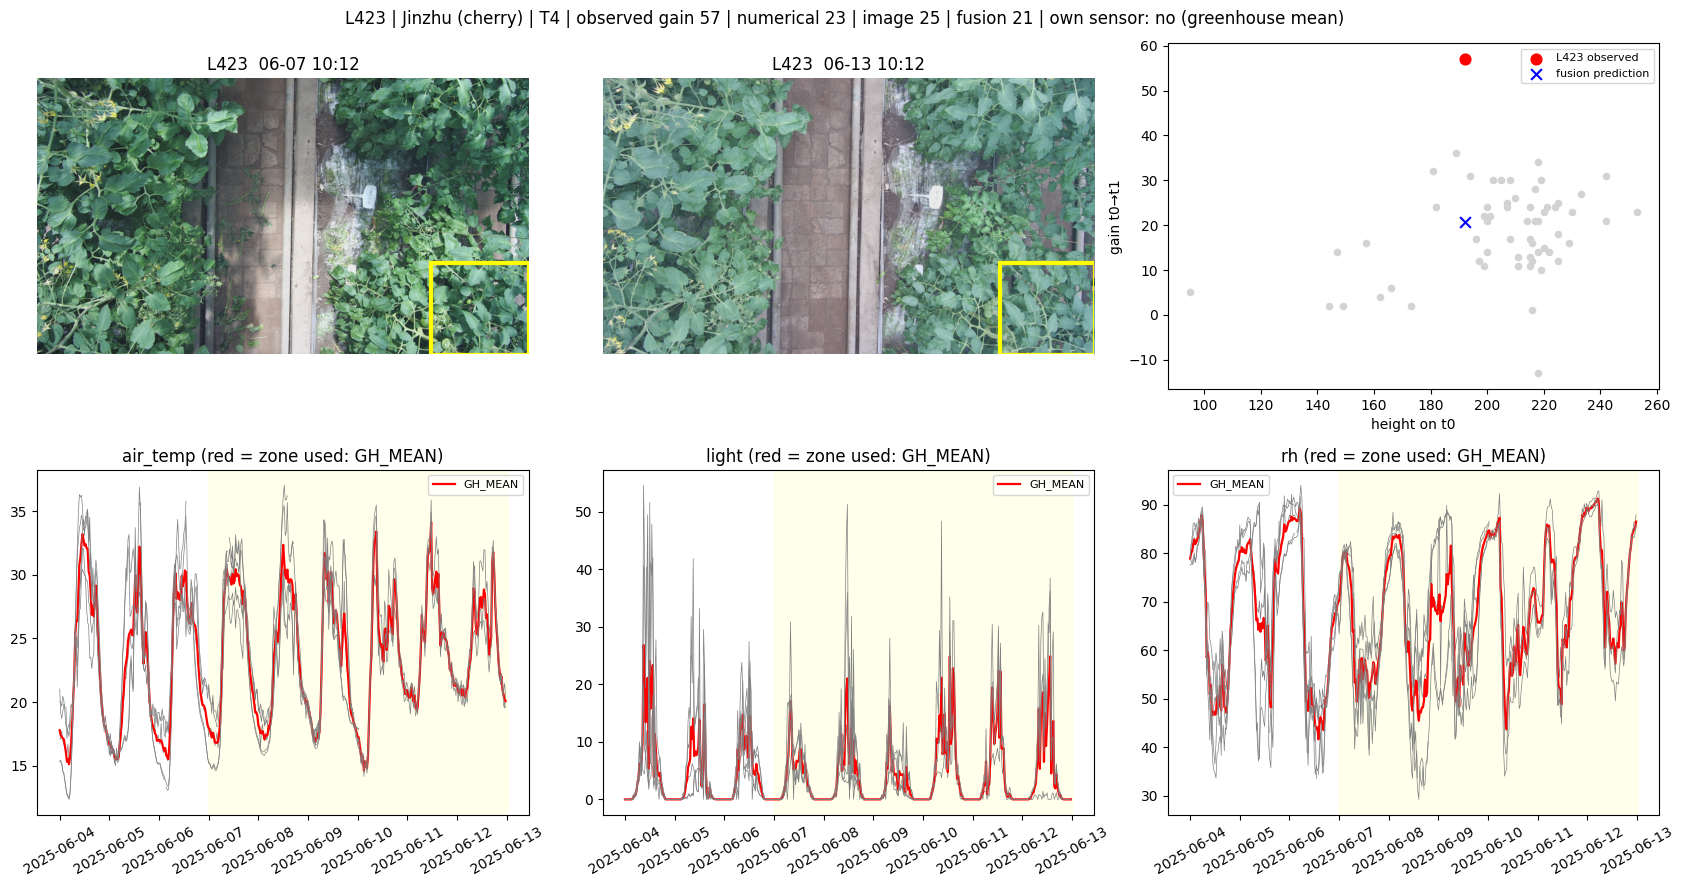

L423 vs other Jinzhu (cherry) plants:


,Plant Height_t0,Stem Diameter_t0,LAI_t0,NDVI_t0,cell_veg_frac_t0,cell_veg_frac_t1,cell_yellow_frac_t0,bed_brightness_delta,temp_mean,light_sum
L423,192.0,14.1,1.68,0.48,0.737075,0.630469,0.001078,0.026944,23.898295,609.764823
peer median,212.5,14.3,1.62,0.44,0.715631,0.668598,0.000447,0.020341,23.867915,578.600949


In [9]:
# Image regions (walkway + cells) were computed and saved by notebook 03 -> no need to repeat that code here
regions = pd.read_parquet(OUT_DIR / 'image_regions.parquet')
WIDTH = int(regions['width'].iloc[0])

def load(rel):
    im = Image.open(MONTH_DIR / rel).convert('RGB'); h = int(im.height * WIDTH / im.width)
    return np.asarray(im.resize((WIDTH, h), Image.BILINEAR)).astype(np.float32) / 255

def bed_plants(token):
    """Same plant layout rule as notebook 03: '111' -> L111..L113 (col 0), L121..L123 (col 1); '11' -> CK11..CK23."""
    out = {}
    if len(token) == 2:
        for v in (1, 2):
            for i, r in enumerate(range(1, 4)): out[f'CK{v}{r}'] = (v - 1, i)
    else:
        t, r0 = token[0], int(token[2])
        for v in (1, 2):
            for i, r in enumerate(range(r0, r0 + 3)): out[f'L{t}{v}{r}'] = (v - 1, i)
    return out

POS = {}
for folder in regions['folder'].unique():
    for side, tok in zip('LR', folder.split(',')):
        for p, (c, r) in bed_plants(tok).items(): POS[p] = (folder, side, c, r)

images['folder'] = images['path'].str.split('/').str[1]
def plant_box(plant, day):
    """First selected image of that day (closest to 10:00) + the plant's cell box."""
    folder, bed, col, row = POS[plant]
    g = regions[(regions.folder == folder) & (regions.day == day) & (regions.bed == bed)
                & (regions['col'] == col) & (regions['row'] == row)]
    g = g.merge(images[['path', 'capture_local', 'hour']], on='path').sort_values('hour')
    r = g.iloc[(g.hour - 10).abs().argsort()].iloc[0]
    return r

def case_study(plant, res_col='res_fus'):
    row = df[df.plant == plant].iloc[0]
    fig = plt.figure(figsize=(17, 9))
    # images t0 / t1 with the plant cell (raw image; features were computed on the illumination-corrected one)
    for k, day in enumerate(['t0', 't1']):
        r = plant_box(plant, day); a = load(r.path); y0, y1, xa, xb = r.y0, r.y1, r.xa, r.xb
        ax = fig.add_subplot(2, 3, k + 1); ax.imshow(a)
        ax.add_patch(plt.Rectangle((xa, y0), xb - xa, y1 - y0, fill=False, ec='yellow', lw=3))
        ax.set_title(f'{plant}  {r.capture_local:%m-%d %H:%M}'); ax.axis('off')
    # where the plant sits among all plants
    ax = fig.add_subplot(2, 3, 3)
    ax.scatter(df['Plant Height_t0'], df['y'], c='lightgray', s=20)
    ax.scatter(row['Plant Height_t0'], row['y'], c='red', s=60, label=f'{plant} observed')
    ax.scatter(row['Plant Height_t0'], row['pred_fus'], c='blue', marker='x', s=60, label='fusion prediction')
    ax.set_xlabel('height on t0'); ax.set_ylabel('gain t0→t1'); ax.legend(fontsize=8)
    # environmental history: the plant's zone vs every zone
    zone = row['sensor_zone']
    w = zone_ts[(zone_ts.time >= T0 - pd.Timedelta(days=3)) & (zone_ts.time < T1)]
    for k, v in enumerate(['air_temp', 'light', 'rh']):
        ax = fig.add_subplot(2, 3, 4 + k)
        for z, g in w.groupby('zone'):
            ax.plot(g.time, g[v], lw=1.6 if z == zone else .5, color='red' if z == zone else 'gray',
                    label=z if z == zone else None)
        ax.axvspan(T0, T1, color='yellow', alpha=.08); ax.set_title(f'{v} (red = zone used: {zone})'); ax.legend(fontsize=8)
        ax.tick_params(axis='x', labelrotation=30)
    fig.suptitle(f"{plant} | {row.variety_name} | {row.treatment} | observed gain {row.y:.0f} | "
                 f"numerical {row.pred_num:.0f} | image {row.pred_img:.0f} | fusion {row.pred_fus:.0f} | "
                 f"own sensor: {'no (greenhouse mean)' if row.zone_is_proxy else 'yes'}", fontsize=12)
    plt.tight_layout(); plt.savefig(FIG_DIR / f'case_{plant}.png', dpi=130); plt.show()

    peers = df[(df.variety_name == row.variety_name)]
    print(f'{plant} vs other {row.variety_name} plants:')
    show = ['Plant Height_t0', 'Stem Diameter_t0', 'LAI_t0', 'NDVI_t0', 'cell_veg_frac_t0', 'cell_veg_frac_t1',
            'cell_yellow_frac_t0', 'bed_brightness_delta', 'temp_mean', 'light_sum']
    show = [c for c in show if c in df]
    display(pd.DataFrame({plant: row[show], 'peer median': peers[show].median()}).T.round(3))

under = df.sort_values('res_fus', ascending=False).iloc[0]['plant']
case_study(under)

**Write your interpretation here (examples of what to look for):**
- *Misleading sensor history*: does this plant have its own sensor? If `zone_is_proxy` is True, the "favourable" temperature/light
  is the greenhouse average, not what this plant experienced.
- *What the image cannot show*: the camera looks down, so stem elongation (height) is mostly invisible; a plant can grow tall
  while its top-down canopy looks the same.
- *Image artefacts*: compare brightness t0 vs t1 — haze/condensation or different light makes colour features change without any plant change.
- *Missing variables*: irrigation events, fertiliser timing, pruning/de-leafing, training of the stem on the string, developmental stage, measurement error.

### 4.2 Detailed case: over-estimated growth

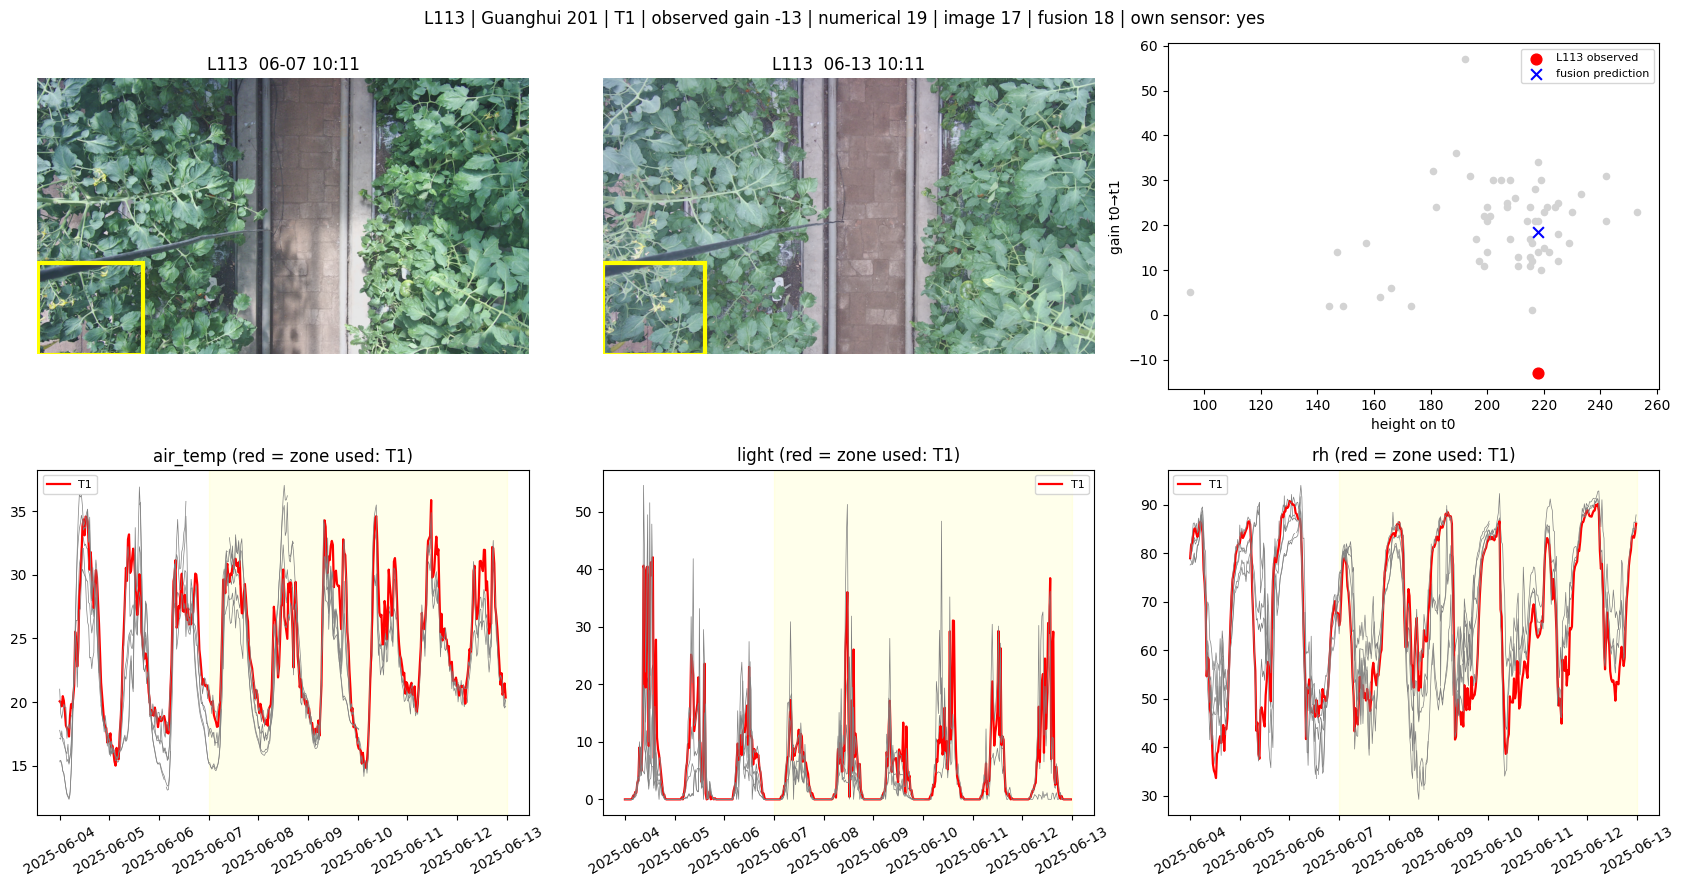

L113 vs other Guanghui 201 plants:


,Plant Height_t0,Stem Diameter_t0,LAI_t0,NDVI_t0,cell_veg_frac_t0,cell_veg_frac_t1,cell_yellow_frac_t0,bed_brightness_delta,temp_mean,light_sum
L113,218.0,16.0,1.66,0.46,0.608451,0.521056,0.003815,-0.029163,24.773549,761.668736
peer median,212.5,13.0,1.61,0.44,0.722953,0.685698,0.000606,0.020341,23.867915,578.600949


In [10]:
over = df.sort_values('res_fus').iloc[0]['plant']
case_study(over)

**Interpretation hints:** a negative height gain is not biologically plausible growth → topping/pruning, a bent or broken stem,
or a measurement error. None of the inputs records management events, so no model can predict this; the honest answer is to
flag it as a data-quality / missing-variable case rather than tune the model to it.

In [11]:
# Save the per-plant predictions for the report
df[['plant', 'camera', 'sensor_zone', 'zone_is_proxy', 'treatment', 'variety_name', 'y',
    'pred_num', 'pred_img', 'pred_fus', 'res_num', 'res_img', 'res_fus']].to_csv(OUT_DIR / 'predictions_per_plant.csv', index=False)
boot.to_csv(OUT_DIR / 'bootstrap_comparison.csv', index=False)
print('Saved results + figures to', OUT_DIR)
print(sorted(p.name for p in FIG_DIR.iterdir()))

Saved results + figures to /content/drive/MyDrive/alprotein_outputs
['case_L113.png', 'case_L423.png', 'model_comparison.png', 'residuals.png']
